<a href="https://colab.research.google.com/github/VincentCCL/ComputationalLexicology/blob/main/WordNet_FrameNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WordNet en FrameNet: Kennisgebaseerde computationele representatie van lexicale betekenis



## Welke lexicale en semantische kennisbanken gebruiken we?

- **Princeton WordNet (PWN):** lexicale kennisbank voor het Engels, georganiseerd rond synsets (woordbetekenissen).
- **Open Multilingual WordNet (OMW):** koppelingen tussen WordNets van verschillende talen.
- **Open Dutch WordNet (ODWN):** lexicale kennisbank voor het Nederlands.
- **ConceptNet:** meertalige kennisgraaf met algemene conceptuele relaties tussen woorden en begrippen.
- **BabelNet:** grote meertalige semantische kennisbank die lexicale en encyclopedische kennis combineert.
- **FrameNet:** beschrijft woordbetekenissen aan de hand van semantische frames en de rollen die daarin voorkomen.

We onderzoeken hoe **woordbetekenissen, conceptuele kennis en semantische relaties computationeel worden gerepresenteerd**.

## Princeton WordNet (PWN)

- Een **Engelstalige lexicale kennisbank**.
- Woordbetekenissen worden georganiseerd in **synsets**.
- Een synset:
  - vertegenwoordigt één specifieke betekenis;
  - bevat woorden die in die betekenis (ongeveer) synoniem zijn.
- Synsets zijn verbonden via **semantische relaties**:
  - hyperonymie en hyponymie;
  - meronymie (deel-geheelrelaties).

### Princeton WordNet en NLTK

- We gebruiken **NLTK** (*Natural Language Toolkit*).
- Daarmee kunnen we:
  - verschillende betekenissen van een woord opvragen;
  - synoniemen binnen een synset bekijken;
  - definities en gebruiksvoorbeelden raadplegen;
  - semantische relaties onderzoeken.
- **Voorbeeld:** het Engelse woord *bank*.

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/Infographic%20met%20synsets%20van%20%E2%80%9Cbank%E2%80%9D.png?raw=true">

In [ ]:
import nltk

# Download Princeton WordNet (eenmalig per omgeving)
nltk.download("wordnet")

from nltk.corpus import wordnet as wn

# Zoek alle synsets voor het woord 'bank'
synsets = wn.synsets("bank")

print(f"Aantal synsets: {len(synsets)}")

for synset in synsets:
    print(synset.name(), ":", synset.definition())


[nltk_data] Downloading package wordnet to /root/nltk_data...


Aantal synsets: 18
bank.n.01 : sloping land (especially the slope beside a body of water)
depository_financial_institution.n.01 : a financial institution that accepts deposits and channels the money into lending activities
bank.n.03 : a long ridge or pile
bank.n.04 : an arrangement of similar objects in a row or in tiers
bank.n.05 : a supply or stock held in reserve for future use (especially in emergencies)
bank.n.06 : the funds held by a gambling house or the dealer in some gambling games
bank.n.07 : a slope in the turn of a road or track; the outside is higher than the inside in order to reduce the effects of centrifugal force
savings_bank.n.02 : a container (usually with a slot in the top) for keeping money at home
bank.n.09 : a building in which the business of banking transacted
bank.n.10 : a flight maneuver; aircraft tips laterally about its longitudinal axis (especially in turning)
bank.v.01 : tip laterally
bank.v.02 : enclose with a bank
bank.v.03 : do business with a bank or 

### De structuur van een synset

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/WordNet-synsetdiagram%20met%20bank.png?raw=true?v=2">



In [ ]:
# Selecteer de eerste synset van 'bank'
synset = wn.synset("bank.n.01")

print("Naam:", synset.name())
print("Definitie:", synset.definition())
print("Voorbeelden:", synset.examples())
print("Lemma's:", synset.lemma_names())
print("Woordsoort:", synset.pos())


Naam: bank.n.01
Definitie: sloping land (especially the slope beside a body of water)
Voorbeelden: ['they pulled the canoe up on the bank', 'he sat on the bank of the river and watched the currents']
Lemma's: ['bank']
Woordsoort: n


### Synsets en lexicale eenheden

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/WordNet-termen%20en%20identificaties.png?raw=true">



### Voorbeeld: *car*

- **Synset:** `car.n.01` — een specifieke betekenis.
- **Lexicale eenheid:** `car.n.01.car` — het lemma *car* in die betekenis.
- NLTK gebruikt hiervoor de objecttypes `Synset` en `Lemma`.



- We onderzoeken de verschillende betekenissen van het Engelse lemma *car*.
- Voor elke betekenis bekijken we de bijbehorende **synset**.
- We bekijken welke **lexicale eenheden** tot elke synset behoren.
- Zo zien we hoe één lemma verschillende betekenissen kan hebben en hoe meerdere lemma's dezelfde betekenis kunnen uitdrukken.

In [ ]:
car_synsets = wn.synsets("car", pos=wn.NOUN)

for synset in car_synsets:
    print("\nSynset:", synset.name())
    print("Definitie:", synset.definition())
    print("Lemma's:", synset.lemma_names())



Synset: car.n.01
Definitie: a motor vehicle with four wheels; usually propelled by an internal combustion engine
Lemma's: ['car', 'auto', 'automobile', 'machine', 'motorcar']

Synset: car.n.02
Definitie: a wheeled vehicle adapted to the rails of railroad
Lemma's: ['car', 'railcar', 'railway_car', 'railroad_car']

Synset: car.n.03
Definitie: the compartment that is suspended from an airship and that carries personnel and the cargo and the power plant
Lemma's: ['car', 'gondola']

Synset: car.n.04
Definitie: where passengers ride up and down
Lemma's: ['car', 'elevator_car']

Synset: cable_car.n.01
Definitie: a conveyance for passengers or freight on a cable railway
Lemma's: ['cable_car', 'car']


#### Synset-object versus lemma-object

- Een **synset-object** vertegenwoordigt een specifieke betekenis.
- Een **lemma-object** vertegenwoordigt een lexicale eenheid binnen die synset.
- De synset `car.n.01` bevat meerdere lemma-objecten.
- Elk lemma-object heeft een eigen identificatie, bijvoorbeeld `car.n.01.automobile`.
- Al deze lemma-objecten verwijzen naar **dezelfde synset**.

In [ ]:
# Vergelijk een synset-object met de bijbehorende lemma-objecten

synset = wn.synset("car.n.01")

print("Synset:", synset)
print("Definition:", synset.definition())

print("\nLemma objects:")
for lemma in synset.lemmas():
    print("Lemma object:", lemma)
    print("Lemma:", lemma.name())
    print("Synset:", lemma.synset())
    print()

Synset: Synset('car.n.01')
Definition: a motor vehicle with four wheels; usually propelled by an internal combustion engine

Lemma objects:
Lemma object: Lemma('car.n.01.car')
Lemma: car
Synset: Synset('car.n.01')

Lemma object: Lemma('car.n.01.auto')
Lemma: auto
Synset: Synset('car.n.01')

Lemma object: Lemma('car.n.01.automobile')
Lemma: automobile
Synset: Synset('car.n.01')

Lemma object: Lemma('car.n.01.machine')
Lemma: machine
Synset: Synset('car.n.01')

Lemma object: Lemma('car.n.01.motorcar')
Lemma: motorcar
Synset: Synset('car.n.01')



### Hyperonymie en hyponymie

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/WordNet-taxonomie%20van%20bank.n.01.png?raw=true">

In [ ]:
synset = wn.synset("bank.n.01")
print("Hyperoniemen:", synset.hypernyms())

Hyperoniemen: [Synset('slope.n.01')]


In [ ]:
main_synset = wn.synset("bank.n.01")

print("Hyperoniemen:")
for synset in main_synset.hypernyms():
    print("-", synset.name(), ":", synset.definition())

print("\nHyponiemen:")
for synset in main_synset.hyponyms():
    print("-", synset.name(), ":", synset.definition())


Hyperoniemen:
- slope.n.01 : an elevated geological formation

Hyponiemen:
- waterside.n.01 : land bordering a body of water
- riverbank.n.01 : the bank of a river


In [ ]:
# Bekijk de volledige hyperoniemhiërarchie
for path in main_synset.hypernym_paths():
    print(" -> ".join(synset.name() for synset in path))


entity.n.01 -> physical_entity.n.01 -> object.n.01 -> geological_formation.n.01 -> slope.n.01 -> bank.n.01


### Oefening: onderzoek een polyseem woord

- Kies een Engels substantief, bijvoorbeeld *paper*, *plant*, *school* of *mouse*.
- Zoek de synsets op met `wn.synsets()`.
- Bekijk de **definities en lemma's**.
- Selecteer twee verschillende betekenissen.
- Onderzoek de **hyperoniemen** van beide synsets.

### Discussie

- Zijn alle betekenissen duidelijk van elkaar te onderscheiden?
- Welke betekenisrelaties worden expliciet weergegeven?
- Welke relaties ontbreken?
- Hoe verschilt dit van een **radiaal betekenisnetwerk** uit de cognitieve semantiek?

## Open Multilingual WordNet (OMW)

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/Open%20Multilingual%20WordNet%20in%20beeld.png?raw=true">


In [ ]:
import nltk
from nltk.corpus import wordnet as wn

# Download de meertalige WordNet-gegevens
nltk.download("omw-1.4")

# Initialiseer de meertalige gegevens
wn.synsets("bank", lang="nld")

# Toon de beschikbare talen
languages = wn.langs()

print(f"Aantal beschikbare talen: {len(languages)}")
print(languages)


[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Aantal beschikbare talen: 32
['eng', 'als', 'arb', 'bul', 'cmn', 'dan', 'ell', 'fin', 'fra', 'heb', 'hrv', 'isl', 'ita', 'ita_iwn', 'jpn', 'cat', 'eus', 'glg', 'spa', 'ind', 'zsm', 'nld', 'nno', 'nob', 'pol', 'por', 'ron', 'lit', 'slk', 'slv', 'swe', 'tha']


### Van een synset naar verschillende talen

- We vertrekken vanuit een **Princeton WordNet-synset**.
- Via OMW kunnen we de gekoppelde lemma's in andere talen opvragen.
- We gebruiken `lemma_names()` met een taalcode:
  - `eng`: Engels
  - `nld`: Nederlands
  - `fra`: Frans
  - `spa`: Spaans
  - `ita`: Italiaans

### Belangrijk

- Woorden die aan dezelfde synset gekoppeld zijn, zijn niet noodzakelijk **exacte vertalingen**.
- Betekenisbereik, register en gebruik kunnen verschillen.

In [ ]:
bank = wn.synset("bank.n.01")

print("Synset:", bank.name())
print("Definitie:", bank.definition())

for lang in ["eng", "nld", "fra", "spa", "ita"]:
    print(lang, ":", bank.lemma_names(lang))


Synset: bank.n.01
Definitie: sloping land (especially the slope beside a body of water)
eng : ['bank']
nld : []
fra : ['banque', 'rive']
spa : ['margen', 'orilla', 'vera']
ita : ['banchina', 'riva']


### Van een Nederlands woord naar synsets

- We kunnen ook vertrekken vanuit een **Nederlands lemma**.
- Met `wn.synsets("bank", lang="nld")` zoeken we de gekoppelde synsets.
- De gevonden synsets behoren tot **Princeton WordNet**.
- De definities zijn daarom in het **Engels**.
- We kunnen ook de Nederlandse lemma's van elke synset opvragen.

### Voorbeeld: *bank*

- Welke betekenissen vinden we?
- Komen die overeen met de Nederlandse betekenisonderscheidingen?

In [ ]:
bank_synsets = wn.synsets("bank", lang="nld")

for synset in bank_synsets:
    print("\nSynset:", synset.name())
    print("Engelse definitie:", synset.definition())
    print("Nederlandse lemma's:", synset.lemma_names("nld"))



Synset: bench.n.01
Engelse definitie: a long seat for more than one person
Nederlandse lemma's: ['bank']

Synset: bench.n.07
Engelse definitie: (law) the seat for judges in a courtroom
Nederlandse lemma's: ['bank', 'zitbank']

Synset: sofa.n.01
Engelse definitie: an upholstered seat for more than one person
Nederlandse lemma's: ['bank', 'canapé', 'sofa']

Synset: workbench.n.01
Engelse definitie: a strong worktable for a carpenter or mechanic
Nederlandse lemma's: ['bank', 'werkbank', 'workmate']

Synset: depository_financial_institution.n.01
Engelse definitie: a financial institution that accepts deposits and channels the money into lending activities
Nederlandse lemma's: ['bank', 'bankieren', 'bankiershuis', 'bankinstelling']

Synset: thrift.n.01
Engelse definitie: any of numerous sun-loving low-growing evergreens of the genus Armeria having round heads of pink or white flowers
Nederlandse lemma's: ['Engels_gras', 'bank']


### Bespreking: het Nederlandse woord *bank*

- Welke betekenissen van *bank* worden gevonden?
- Zijn alle gevonden betekenissen relevant voor het Nederlands?
- Ontbreken er betekenissen?
- Zijn de koppelingen met Princeton WordNet altijd correct?

### Belangrijk

- De betekenisonderscheidingen zijn afhankelijk van de **Engelse synsetinventaris**.
- OMW geeft dus niet noodzakelijk een volledige beschrijving van Nederlandse woordbetekenissen.

### Vertalen op basis van betekenis

- Eén lemma kan verschillende betekenissen hebben.
- Die betekenissen kunnen **verschillende vertalingen** vereisen.
- WordNet laat ons vertalingen zoeken op het niveau van een **synset**.

#### Voorbeeld: *bank*

- *bank* (financiële instelling) → Engels *bank*
- *bank* (zitmeubel) → Engels *bench*

- We selecteren eerst de betekenis en zoeken vervolgens de equivalenten.
- Dit noemen we **sense-based lexical linking**.

In [ ]:
# Twee verschillende betekenissen van 'bank'
financial_bank = wn.synset("depository_financial_institution.n.01")
bench = wn.synset("bench.n.01")

for synset in [financial_bank, bench]:
    print("\nBetekenis:", synset.definition())

    for lang in ["eng", "nld", "fra", "ita"]:
        print(lang, ":", synset.lemma_names(lang))



Betekenis: a financial institution that accepts deposits and channels the money into lending activities
eng : ['depository_financial_institution', 'bank', 'banking_concern', 'banking_company']
nld : ['bank', 'bankieren', 'bankiershuis', 'bankinstelling']
fra : ['banque']
ita : ['banca', 'banco', 'cassa']

Betekenis: a long seat for more than one person
eng : ['bench']
nld : ['bank']
fra : ['banc']
ita : ['banco', 'panca']


### Zijn gekoppelde woorden exacte vertalingen?

- Twee woorden kunnen aan dezelfde synset gekoppeld zijn.
- Toch hoeven ze niet in alle contexten uitwisselbaar te zijn.

### Mogelijke verschillen

- **Betekenisbereik:** de ene term is ruimer dan de andere.
- **Register:** formeel versus informeel.
- **Connotatie:** gevoelswaarde en associaties.
- **Collocaties:** combinaties met andere woorden.
- **Culturele context:** taal- of cultuurgebonden begrippen.


### Oefening: *agenda* in OMW en het ANW

- In eerdere lessen onderzochten we *agenda* met:
  - het **Algemeen Nederlands Woordenboek (ANW)**;
  - concordanties;
  - **Word Sense Induction** in Sketch Engine.

### Opdracht

- Zoek de synsets van *agenda* in OMW.
- Bekijk de Engelse definities.
- Onderzoek de Nederlandse, Engelse en Franse lemma's.
- Vergelijk de betekenisindeling met die van het **ANW**.

### Reflectie

- Welke ANW-betekenissen ontbreken in OMW?
- Welke betekenissen worden anders afgebakend?
- Wat zegt dit over het gebruik van een Engelstalige synsetinventaris?

### Conclusie

Met **Open Multilingual WordNet** kunnen we:

- Lexicale equivalenten in verschillende talen opzoeken.
- Vanuit een Nederlands lemma gekoppelde PWN-synsets vinden.
- Vertalingen onderscheiden op basis van betekenis.
- Betekenisonderscheidingen tussen talen vergelijken.

### Beperkingen

- Niet alle Nederlandse betekenissen zijn vertegenwoordigd.
- Betekenisgrenzen verschillen tussen talen.
- Een synsetkoppeling garandeert geen volledige vertaalequivalentie.
- De kwaliteit hangt af van de beschikbare lexicale bronnen en koppelingen.

## Open Dutch WordNet (ODWN)

- In **Open Multilingual WordNet (OMW)** vertrekken we vanuit de synsets van Princeton WordNet.
- Nederlandse woorden worden gekoppeld aan deze Engelse betekenisindeling.
- Maar **betekenisonderscheidingen verschillen tussen talen**.
- **Open Dutch WordNet (ODWN)** biedt een eigen Nederlandse betekenisinventaris.

### Centrale vraag

- Hoe kunnen we Nederlandse woordbetekenissen beschrijven zonder de Engelse synsetinventaris als uitgangspunt te nemen?

### Open Dutch WordNet in Python

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/ODWN_%20Dutch_WordNet%20in%20beeld.png?raw=true">


In [ ]:
import sys
from pathlib import Path

repo = Path("/content/OpenDutchWordnet")

if not repo.exists():
    !git clone -q https://github.com/cltl/OpenDutchWordnet.git

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src/cltl/odwn"))

from wn_grid_parser import Wn_grid_parser

odwn = Wn_grid_parser(
    str(repo / "resources/odwn/odwn_orbn_gwg-LMF_1.3.xml.gz")
)


### Lexicale eenheden opzoeken

<img src="https://github.com/VincentCCL/ComputationalLexicology/blob/main/Lexicale%20eenheden%20van%20bank%20inODWN.png?raw=true?v=1">


In [ ]:
word = "bank"
entries = list(odwn.lemma_get_generator(word, pos="noun"))

for entry in sorted(entries, key=lambda e: int(e.get_sense_number())):
    print(entry.get_id(), ":", entry.get_definition() or "(geen definitie)")

bank-n-1 : zitmeubel
bank-n-2 : geldverlenende instelling
bank-n-3 : zandbank
bank-n-4 : wolkenbank
bank-n-5 : bij het kaarten
bank-n-6 : bankgebouw
bank-n-7 : werkbank
bank-n-8 : (geen definitie)
bank-n-9 : (geen definitie)
bank-n-10 : (geen definitie)


### Van lexicale eenheden naar synsets

- Elke lexicale eenheid kan gekoppeld zijn aan een **synset**.
- Met `get_synset_id()` vragen we de identificatie op.

In ODWN komen verschillende soorten synset-ID's voor:

- `eng-30-02828884-n`: gebaseerd op Princeton WordNet 3.0.
- `odwn-10-108029334-n`: specifiek voor ODWN.

Daarnaast kunnen synsets een **ILI-identificatie** hebben, bijvoorbeeld `i50698`, om overeenkomstige concepten tussen WordNets te verbinden.

**Let op:**
- Niet elke synset heeft een ILI.
- Niet elke lexicale eenheid heeft een synsetkoppeling.
- Een bestaande koppeling is niet noodzakelijk inhoudelijk correct.

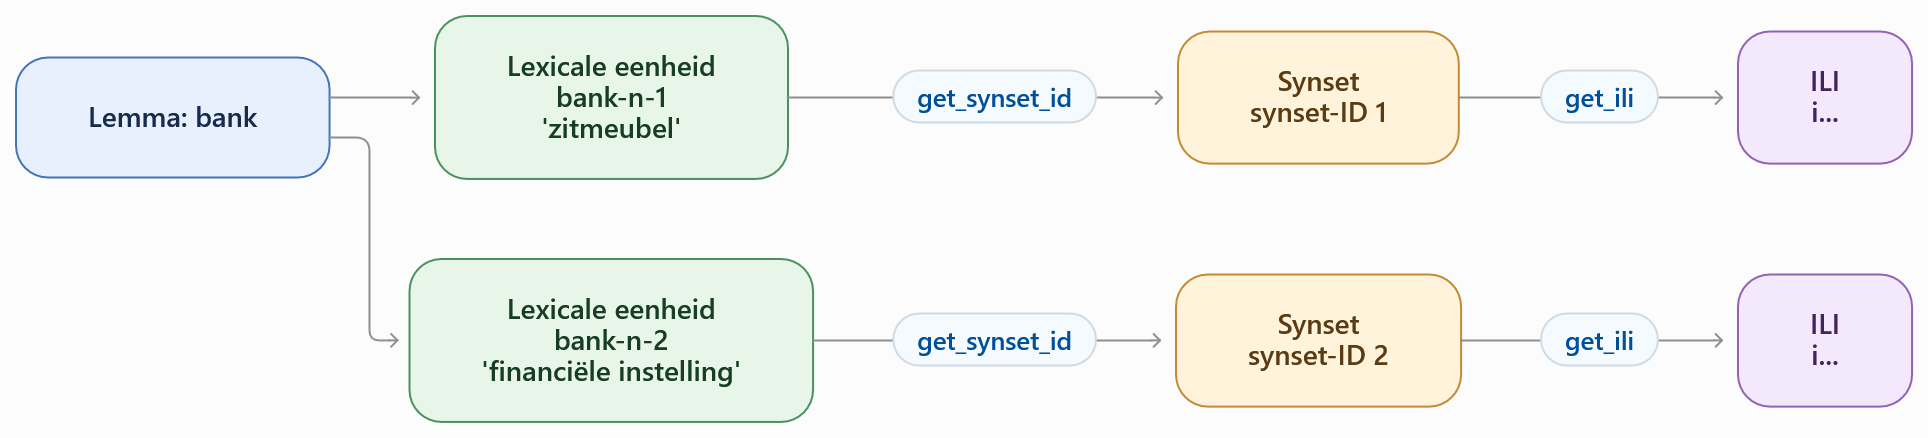

In [ ]:
# From lexical entries to synsets and ILIs

for entry in sorted(entries, key=lambda e: int(e.get_sense_number())):
    synset_id = entry.get_synset_id()
    synset = odwn.synsets_find_synset(synset_id) if synset_id else None

    print("Lexicale eenheid:", entry.get_id())
    print("Synset:", synset_id or "(geen koppeling)")
    print("ILI:", synset.get_ili() if synset else None)
    print()

Lexicale eenheid: bank-n-1
Synset: eng-30-02828884-n
ILI: i50698

Lexicale eenheid: bank-n-2
Synset: eng-30-08420278-n
ILI: i81364

Lexicale eenheid: bank-n-3
Synset: odwn-10-108029334-n
ILI: None

Lexicale eenheid: bank-n-4
Synset: (geen koppeling)
ILI: None

Lexicale eenheid: bank-n-5
Synset: odwn-10-101406353-n
ILI: None

Lexicale eenheid: bank-n-6
Synset: odwn-10-100561848-n
ILI: None

Lexicale eenheid: bank-n-7
Synset: eng-30-04600486-n
ILI: i61248

Lexicale eenheid: bank-n-8
Synset: eng-30-04256520-n
ILI: i59184

Lexicale eenheid: bank-n-9
Synset: eng-30-02829116-n
ILI: i50699

Lexicale eenheid: bank-n-10
Synset: eng-30-12098827-n
ILI: i100738



## Intermezzo: hoe betrouwbaar zijn synsetkoppelingen?

**Sevens, Vandeghinste & Van Eynde (2014)**
[*Improving the Precision of Synset Links Between Cornetto and Princeton WordNet*](https://aclanthology.org/S16-2017/). COLING 2014 Workshop on Lexical and Grammatical Resources for Language Processing (LG-LP 2014)

- **Cornetto:** een Nederlandse lexicale kennisbank, voorloper van ODWN.
- Onderzoek naar de kwaliteit van koppelingen met **Princeton WordNet**.
- **300** willekeurig geselecteerde Cornetto-synsets.
- Samen goed voor **998** synsetkoppelingen.
- De koppelingen werden handmatig beoordeeld.

### Resultaat

**35,27% van de koppelingen was foutief.**

### Waarom zijn synsetkoppelingen soms fout?

- Koppelingen tussen Nederlandse en Engelse synsets werden deels **automatisch tot stand gebracht**.
- **Polysemie:** een Nederlands woord wordt aan de verkeerde Engelse betekenis gekoppeld.
- **Verschillen tussen talen:** Nederlandse en Engelse betekenisonderscheidingen komen niet altijd overeen.
- **Onvoldoende semantische controle:** overeenkomstige woorden betekenen niet noodzakelijk hetzelfde.

### Kernprobleem

**Automatische linking kan foutieve betekenisrelaties opleveren**, ook wanneer de koppelingen technisch geldig zijn.

### Automatische controle van synsetkoppelingen

**Sevens et al. (2014): een methode op basis van vertaalinformatie**

1. Verzamel Nederlands-Engelse vertalingen uit:
   - tweetalige woordenboeken (Wiktionary, FreeDict);
   - parallelle corpora (Europarl, OPUS).
2. Neem de Nederlandse lemma's uit een Cornetto-synset.
3. Zoek hun Engelse vertalingen op.
4. Vergelijk die vertalingen met:
   - de lemma's van de gekoppelde PWN-synset;
   - de woorden in de Engelse definitie (*gloss*).
5. Bereken een **betrouwbaarheidsscore** voor de koppeling.

### Voorbeeld: hoe beoordelen we een synsetkoppeling?

**Nederlandse Cornetto-synset**
- Lemma's: *snoepgoed*, *snoep*
- Betekenis: zoete lekkernijen

**Gekoppelde Princeton WordNet-synset**
- Lemma's: *candy*, *confect*
- Engelse definitie: beschrijft zoete voedingswaren

**Stap 1 — Zoek Engelse vertalingen**
- We zoeken vertalingen van *snoepgoed* en *snoep* in tweetalige bronnen.
- *candy* komt daarbij **twee keer** voor.

**Stap 2 — Vergelijk met de Engelse synset**
- Overlap met synsetlemma's: *candy* (2 keer).
- Genormaliseerde overlap: **2/3 = 66,67%**.

**Stap 3 — Vergelijk met de Engelse definitie**
- Overlappend definitiewoord: *sweet* (2 keer).
- Genormaliseerde overlap: **2/8 = 25%**.

### Van overlap naar betrouwbaarheidsscore

| Vergelijking | Overlap | Score |
|---|---|---|
| Vertalingen ↔ Engelse synsetlemma's | `candy` × 2 | 2/3 = 66,67% |
| Vertalingen ↔ Engelse definitiewoorden | `sweet` × 2 | 2/8 = 25% |

De **betrouwbaarheidsscore** is het gemiddelde:

$$
C(S,T)=\frac{1}{2}
\left(\frac{2}{3}+\frac{2}{8}\right)
=\boxed{45{,}83\%}
$$

**Interpretatie**
- Meer overlap levert een hogere betrouwbaarheidsscore op.
- Herhaalde vertalingen leveren extra bewijs.
- Een score van 45,83% is **geen kans van 45,83% dat de koppeling correct is**.
- Sevens et al. verwijderen koppelingen met een score van **0%**.

### Automatische evaluatie van synsetkoppelingen

Sevens et al. (2014) gebruiken onder meer:

- **Tweetalige lexicale informatie** om Nederlandse en Engelse betekenissen te vergelijken.
- **Vertaalinformatie** om de plausibiliteit van koppelingen te beoordelen.
- Een methode om minder betrouwbare koppelingen te identificeren.

### Resultaat

- Foutpercentage vóór filtering: **35,27%**.
- Foutpercentage na filtering: **21,09%**.

**Conclusie:** automatische methoden kunnen de kwaliteit verbeteren.

### Oefening: hoe betrouwbaar zijn de ODWN-koppelingen?

We voeren een kleine handmatige evaluatie uit, geïnspireerd op Sevens et al. (2014).

- Selecteer **10 willekeurige ODWN-lexicale eenheden** met een koppeling naar Princeton WordNet.
- Vergelijk voor elke koppeling:
  - het **Nederlandse lemma** en de definitie in ODWN;
  - de **Engelse synsetlemma's** en definitie in PWN.
- Beoordeel of beide dezelfde betekenis vertegenwoordigen:

  - `1` = correcte koppeling
  - `0` = foutieve koppeling
  - `?` = onzeker

#### Bespreking

- Welke koppelingen zijn foutief?
- Welke zijn moeilijk te beoordelen, en waarom?
- Welk percentage van de beoordeelde koppelingen is correct?

In [ ]:
import random

random.seed(42)
sample = []
count = 0
nr_of_entries = 10

for entry in odwn.les_get_generator():
    synset_id = entry.get_synset_id()
    definition = entry.get_definition()

    if synset_id and synset_id.startswith("eng-30-") and definition and definition.strip():
        count += 1
        if len(sample) < nr_of_entries:
            sample.append(entry)
        else:
            j = random.randrange(count)
            if j < nr_of_entries:
                sample[j] = entry

print(f"{len(sample)} lexicale eenheden geselecteerd.")

10 lexicale eenheden geselecteerd.


### Oefening: beoordeel de synsetkoppelingen

Voor elke geselecteerde koppeling tonen we:

- De **Nederlandse lexicale eenheid** en haar definitie.
- Alle **Nederlandse lemma's** van de bijbehorende synset.
- De **Engelse lemma's** en definitie van de gekoppelde PWN-synset.

**Beoordeel of beide synsets dezelfde betekenis vertegenwoordigen:**

- `1` = correcte koppeling
- `0` = foutieve koppeling
- `?` = onzeker

De beoordelingen worden opgeslagen in een **pandas DataFrame**.

Na afloop berekenen we de **precisie**: het aandeel correcte koppelingen onder de koppelingen die we als correct of foutief konden beoordelen.

In [ ]:
import pandas as pd

results = []

for i, entry in enumerate(sample, start=1):
    synset_id = entry.get_synset_id()
    _, _, offset, pos = synset_id.split("-")
    pwn_synset = wn.synset_from_pos_and_offset(pos, int(offset))

    dutch_entries = odwn.les_all_les_of_one_synset(synset_id)
    dutch_lemmas = sorted(set(e.get_lemma() for e in dutch_entries))

    print(f"\n{i}. {entry.get_lemma()} ({entry.get_id()})")
    print("Dutch lemmas:", ", ".join(dutch_lemmas))
    print("Dutch definition:", entry.get_definition())
    print("English lemmas:", ", ".join(pwn_synset.lemma_names()))
    print("English definition:", pwn_synset.definition())

    while True:
        judgment = input("Correct link? (1 = yes, 0 = no, ? = unsure): ")
        if judgment in ["1", "0", "?"]:
            break
        print("Please enter 1, 0 or ?.")

    results.append({
        "lemma": entry.get_lemma(),
        "dutch_lemmas": ", ".join(dutch_lemmas),
        "odwn_entry": entry.get_id(),
        "pwn_synset": pwn_synset.name(),
        "judgment": judgment
    })

df = pd.DataFrame(results)

print("\nEvaluation results:")
display(df)

evaluated = df[df["judgment"].isin(["0", "1"])]

if len(evaluated) > 0:
    precision = (evaluated["judgment"] == "1").mean()
    print(f"\nPrecision: {precision:.1%}")
    print(f"Evaluated links: {len(evaluated)}")
    print(f"Uncertain links: {(df['judgment'] == '?').sum()}")


1. verzekeren (verzekeren-v-3)
Dutch lemmas: assureren, verzekeren
Dutch definition: verzekering afsluiten
English lemmas: insure
English definition: take out insurance for


KeyboardInterrupt: Interrupted by user

### Oefening: onderzoek een zelfgekozen woord

- Kies een Nederlands lemma, bijvoorbeeld *agenda*.
- Bekijk de verschillende **lexicale eenheden** in ODWN.
- Vergelijk de Nederlandse betekenissen met de gekoppelde PWN-synsets.
- Beoordeel elke koppeling (`1`, `0` of `?`).
- Voeg de beoordelingen toe aan onze bestaande resultaten.

**Vraag:**
- Zijn alle betekenissen van het Nederlandse woord vertegenwoordigd?
- Zijn de bestaande koppelingen correct?
- Wat is het verschil tussen **correctheid** en **volledigheid** van de koppelingen?

In [ ]:
word = input("Enter a Dutch word [agenda]: ").strip() or "agenda"

entries = sorted(
    odwn.lemma_get_generator(word),
    key=lambda e: int(e.get_sense_number())
)

new_results = []

if not entries:
    print(f"No entries found for '{word}'.")

for i, entry in enumerate(entries, start=1):
    synset_id = entry.get_synset_id()

    print(f"\n--- Meaning {i}/{len(entries)} ---")
    print(f"Lexical entry: {entry.get_lemma()} ({entry.get_id()})")
    print("Dutch definition:", entry.get_definition() or "Not available")

    if not synset_id or not synset_id.startswith("eng-30-"):
        print("No direct Princeton WordNet link.")
        continue

    dutch_entries = odwn.les_all_les_of_one_synset(synset_id)
    dutch_lemmas = sorted(set(e.get_lemma() for e in dutch_entries))

    _, _, offset, pos = synset_id.split("-")
    pwn_synset = wn.synset_from_pos_and_offset(pos, int(offset))

    print("Dutch lemmas:", ", ".join(dutch_lemmas))
    print("English lemmas:", ", ".join(pwn_synset.lemma_names()))
    print("English definition:", pwn_synset.definition())

    while True:
        judgment = input("Correct link? (1 = yes, 0 = no, ? = unsure): ").strip()
        if judgment in ["1", "0", "?"]:
            break
        print("Please enter 1, 0 or ?.")

    new_results.append({
        "lemma": entry.get_lemma(),
        "dutch_lemmas": ", ".join(dutch_lemmas),
        "odwn_entry": entry.get_id(),
        "pwn_synset": pwn_synset.name(),
        "judgment": judgment
    })

# Add new evaluations to the existing DataFrame
if new_results:
    df = pd.concat([df, pd.DataFrame(new_results)], ignore_index=True)

    # Keep the most recent evaluation of each lexical entry
    df = df.drop_duplicates(subset="odwn_entry", keep="last")

print("\nUpdated evaluation results:")
display(df)

evaluated = df[df["judgment"].isin(["0", "1"])]

if len(evaluated) > 0:
    precision = (evaluated["judgment"] == "1").mean()
    print(f"\nPrecision: {precision:.1%}")
    print(f"Evaluated links: {len(evaluated)}")
    print(f"Uncertain links: {(df['judgment'] == '?').sum()}")
else:
    print("No links could be evaluated.")

Enter a Dutch word [agenda]: 

--- Meaning 1/4 ---
Lexical entry: agenda (agenda-n-1)
Dutch definition: afsprakenboekje
Dutch lemmas: agenda
English lemmas: diary
English definition: a personal journal (as a physical object)
Correct link? (1 = yes, 0 = no, ? = unsure): ?

--- Meaning 2/4 ---
Lexical entry: agenda (agenda-n-2)
Dutch definition: lijst van onderwerpen
Dutch lemmas: agenda, dagindeling, plan, programma, schema, tijdpad, tijdplan, tijdschema
English lemmas: agenda, docket, schedule
English definition: a temporally organized plan for matters to be attended to
Correct link? (1 = yes, 0 = no, ? = unsure): ?

--- Meaning 3/4 ---
Lexical entry: agenda (agenda-n-3)
Dutch definition: Not available
Dutch lemmas: agenda, borderel
English lemmas: agenda, agendum, order_of_business
English definition: a list of matters to be taken up (as at a meeting)
Correct link? (1 = yes, 0 = no, ? = unsure): ?

--- Meaning 4/4 ---
Lexical entry: agenda (agenda-n-4)
Dutch definition: Not available


NameError: name 'df' is not defined

## ConceptNet: een ander soort semantisch netwerk

<img src="https://opendatascience.com/wp-content/uploads/2017/03/conceptnet-example-560x300.png">

- **WordNet:** organiseert woordbetekenissen in synsets en semantische relaties.
- **ConceptNet:** een meertalige kennisgraaf met relaties tussen concepten.
- Bevat naast lexicale relaties ook **algemene wereldkennis** (*commonsense knowledge*).

### Voorbeelden van relaties

- `IsA`: een hond is een dier.
- `PartOf`: een wiel is onderdeel van een auto.
- `UsedFor`: een mes wordt gebruikt om te snijden.
- `CapableOf`: een vogel kan vliegen.
- `AtLocation`: een boek bevindt zich vaak in een bibliotheek.

### Belangrijk verschil

**WordNet beschrijft vooral lexicale betekenis; ConceptNet legt ook verbanden met alledaagse wereldkennis.**

In [ ]:
import requests
import zipfile
import pandas as pd
from pathlib import Path

url = "https://www.ccl.kuleuven.be/~vincent/CompLex/conceptnet_nl.zip"
zip_path = Path("/content/conceptnet_nl.zip")
data_dir = Path("/content/conceptnet")

# Download only if necessary
if not zip_path.exists():
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    zip_path.write_bytes(response.content)

# Extract the archive
data_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(data_dir)

# Find the TSV file
tsv_path = next(data_dir.rglob("conceptnet_nl.tsv"))

# Load into pandas
cn = pd.read_csv(
    tsv_path,
    sep="\t",
    header=None,
    names=["relation", "start", "end", "metadata"]
)

print(f"Loaded {len(cn):,} Dutch ConceptNet relations.")
display(cn.head())

Loaded 166,893 Dutch ConceptNet relations.


,relation,start,end,metadata
0,/r/Antonym,/c/nl/aanbodcurve/n,/c/nl/vraagcurve,"{""dataset"": ""/d/wiktionary/en"", ""license"": ""cc..."
1,/r/Antonym,/c/nl/aanbodelasticiteit/n,/c/nl/aanbodinelasticiteit,"{""dataset"": ""/d/wiktionary/en"", ""license"": ""cc..."
2,/r/Antonym,/c/nl/aandoen/v,/c/nl/uitdoen,"{""dataset"": ""/d/wiktionary/en"", ""license"": ""cc..."
3,/r/Antonym,/c/nl/aandraaien/v,/c/nl/losdraaien,"{""dataset"": ""/d/wiktionary/fr"", ""license"": ""cc..."
4,/r/Antonym,/c/nl/aandraaien/v,/c/nl/uitdoen,"{""dataset"": ""/d/wiktionary/fr"", ""license"": ""cc..."


In [ ]:
from urllib.parse import quote, unquote

def conceptnet_lookup(word):
    concept = "/c/nl/" + quote(
        word.strip().lower().replace(" ", "_"), safe=""
    )

    matches = cn[
        cn["start"].eq(concept) |
        cn["end"].eq(concept) |
        cn["start"].str.startswith(concept + "/") |
        cn["end"].str.startswith(concept + "/")
    ]

    for _, edge in matches.iterrows():
        start = unquote(edge["start"].split("/")[3]).replace("_", " ")
        end = unquote(edge["end"].split("/")[3]).replace("_", " ")
        relation = edge["relation"].split("/")[-1]

        print(f"{start} --{relation}--> {end}")

    print(f"\n{len(matches)} relations found.")

### Hoe werd ConceptNet opgebouwd?

ConceptNet is niet van nul af aan handmatig samengesteld. Het combineert
informatie uit verschillende bestaande bronnen:

- **Open Mind Common Sense:** uitspraken over alledaagse kennis, verzameld bij vrijwilligers.
- **Wiktionary:** informatie uit een gezamenlijk opgebouwde woordenlijst.
- **WordNet:** lexicale en semantische relaties.
- **Andere bronnen:** onder meer DBpedia en OpenCyc.

De informatie uit deze bronnen werd omgezet naar een gemeenschappelijke
voorstelling: **concept — relatie — concept**.

### Discussie

- Wat zijn de voordelen van deze aanpak?
- Welke problemen kunnen ontstaan wanneer informatie uit verschillende
  bronnen wordt samengevoegd?
- Hoe betrouwbaar is kennis die door vrijwilligers werd aangeleverd?

**Referentie:** [Speer, Chin & Havasi (2017)](https://arxiv.org/abs/1612.03975)

In [ ]:
conceptnet_lookup("hond")

een bouwvakker --AtLocation--> hond
hond --AtLocation--> bomen
hond --AtLocation--> een fiets
hond --AtLocation--> een gebouw
hond --AtLocation--> een huis
klei --AtLocation--> hond
vogels --AtLocation--> hond
water --AtLocation--> hond
zand --AtLocation--> hond
een kok --CapableOf--> hond
een mens --CapableOf--> hond
hond --CapableOf--> te leren
kat --CapableOf--> hond
koe --CapableOf--> hond
water --CapableOf--> hond
eten --CreatedBy--> hond
hond --CreatedBy--> een kok
bloedhond --DerivedFrom--> hond
bulhond --DerivedFrom--> hond
dashond --DerivedFrom--> hond
hondachtig --DerivedFrom--> hond
hondenbrok --DerivedFrom--> hond
hondenhok --DerivedFrom--> hond
hondenlijn --DerivedFrom--> hond
hondenlul --DerivedFrom--> hond
hondenmoeder --DerivedFrom--> hond
hondenras --DerivedFrom--> hond
hondenstront --DerivedFrom--> hond
hondenwacht --DerivedFrom--> hond
hondenweer --DerivedFrom--> hond
hondsbrutaal --DerivedFrom--> hond
hondstrouw --DerivedFrom--> hond
hondsvot --DerivedFrom--> hond
h

In [ ]:
import json

# Zoek de relatie 'mens --IsA--> hond'
matches = cn[
    (cn["relation"] == "/r/IsA")
    & (cn["start"] == "/c/nl/mens")
    & (cn["end"] == "/c/nl/hond")
]

# Toon de relatie en alle beschikbare metadata
for _, edge in matches.iterrows():
    print("Relatie:", edge["start"], edge["relation"], edge["end"])
    print("Metadata:")
    print(json.dumps(
        json.loads(edge["metadata"]),
        indent=2,
        ensure_ascii=False
    ))

Relatie: /c/nl/mens /r/IsA /c/nl/hond
Metadata:
{
  "dataset": "/d/conceptnet/4/nl",
  "license": "cc:by/4.0",
  "sources": [
    {
      "activity": "/s/activity/omcs/csamoa4_self_rating",
      "contributor": "/s/contributor/omcs/bosamber"
    }
  ],
  "surfaceEnd": "hond",
  "surfaceStart": "mens",
  "surfaceText": "[[mens]] is een soort [[hond]].",
  "weight": 1.0
}


### Kritische bespreking: hoe betrouwbaar is ConceptNet?

We vonden een opmerkelijke relatie:

`mens --IsA--> hond`

**Interpretatie**
- Is deze relatie fout?
- Kan *hond* hier een figuurlijke betekenis hebben?
- Hoe zou WordNet verschillende betekenissen van *hond* voorstellen?

**Herkomst**
- Uit welke bron komt deze relatie?
- Kunnen we achterhalen waarom ze werd opgenomen?
- Wat vertelt het `weight`-veld ons? Is dit een garantie voor correctheid?

**Algemene discussie**
- Welke problemen ontstaan wanneer woordbetekenissen niet duidelijk
  worden onderscheiden?
- Is een grote hoeveelheid kennis noodzakelijk ook betrouwbare kennis?
- Voor welke toepassingen zou je eerder WordNet gebruiken, en voor welke ConceptNet?

### Conclusie

ConceptNet combineert **lexicale kennis en algemene wereldkennis** uit
verschillende bronnen. Dat levert een rijke kennisgraaf op, maar kan
ook leiden tot **dubbelzinnige, onnauwkeurige of foutieve relaties**.

De herkomst van de informatie is daarom belangrijk bij het beoordelen
van de betrouwbaarheid.

## BabelNet: een meertalig semantisch netwerk

**[BabelNet](https://babelnet.org/)** combineert lexicale en encyclopedische kennis uit
verschillende bronnen, waaronder WordNet en Wikipedia.

- Organiseert betekenissen en concepten in **Babel-synsets**.
- Verbindt woorden en uitdrukkingen uit verschillende talen.
- Bevat zowel **algemene begrippen** als **eigennamen**,
  bijvoorbeeld personen, steden en organisaties.
- Legt relaties tussen betekenissen en verbindt ze met
  encyclopedische informatie.

### Vergelijking

- **WordNet:** nauwkeurig beschreven lexicale betekenissen.
- **ConceptNet:** relaties tussen concepten en algemene wereldkennis.
- **BabelNet:** grootschalige koppeling van lexicale en
  encyclopedische kennis over talen heen.



In [ ]:
from google.colab import userdata
api_key=userdata.get('BABELNET_API_KEY')

### Polysemie in BabelNet

We zoeken de verschillende betekenissen van het Nederlandse woord *bank*.

Voor elke betekenis bekijken we:
- de **Babel-synset**;
- Nederlandse en Engelse synsetlemma's;
- de beschikbare definities.

**Vergelijk met ODWN:** vinden we dezelfde betekenissen?

In [ ]:
import requests

def babelnet_get(endpoint, **params):
    response = requests.get(
        f"https://babelnet.io/v9/{endpoint}",
        params={**params, "key": api_key},
        headers={"Accept-Encoding": "gzip"},
        timeout=30
    )
    response.raise_for_status()
    return response.json()

word = input("Geef een Nederlands woord [bank]: ").strip() or "bank"

synset_ids = babelnet_get(
    "getSynsetIds",
    lemma=word,
    searchLang="NL",
    pos="NOUN"
)

print(f"\nGevonden synsets voor '{word}': {len(synset_ids)}")

# Beperk het aantal API-aanvragen
for i, item in enumerate(synset_ids[:10], start=1):
    synset_id = item["id"]

    synset = babelnet_get(
        "getSynset",
        id=synset_id,
        targetLang=["NL", "EN"]
    )

    print(f"\n--- {i}. {synset_id} ---")
    print("Type:", synset.get("synsetType"))

    for lang in ["NL", "EN"]:
        lemmas = sorted({
            sense["properties"]["fullLemma"].replace("_", " ")
            for sense in synset.get("senses", [])
            if sense.get("properties", {}).get("language") == lang
        })

        print(f"{lang}:", ", ".join(lemmas[:10]) or "(geen lemma)")

        definitions = [
            gloss["gloss"]
            for gloss in synset.get("glosses", [])
            if gloss.get("language") == lang
        ]

        if definitions:
            print(f"Definitie ({lang}):", definitions[0])

Geef een Nederlands woord [bank]: agenda

Gevonden synsets voor 'agenda': 15

--- 1. bn:00014706n ---
Type: CONCEPT
NL: agenda, kalender, schema
EN: calendar
Definitie (EN): A list or register of events (appointments or social events or court cases etc)

--- 2. bn:00001967n ---
Type: CONCEPT
NL: agenda, dagindeling, plan, programma, schema, tijdpad, tijdplan, tijdschema
EN: agenda, docket, schedule
Definitie (EN): A temporally organized plan for matters to be attended to

--- 3. bn:00001968n ---
Type: CONCEPT
NL: Agenda, agenda, agenda (vergadering), agendavoorstel, agendum, borderel, programma, regeling van de werkzaamheden
Definitie (NL): Een agendavoorstel is een onderwerpenlijst met de te bespreken onderwerpen voor een vergadering.
EN: Call for orders of the day, agenda, agenda (meeting), agendas, agendum, calendar, call for the orders of the day, docket, general order (parliamentary procedure), meeting agenda
Definitie (EN): A list of matters to be taken up (as at a meeting)

--- 

### Betekenisgericht vertalen met BabelNet

Een woord kan verschillende vertalingen hebben, afhankelijk van de betekenis.

Bijvoorbeeld:
- *bank* als financiële instelling;
- *bank* als zitmeubel.

BabelNet koppelt woorden uit verschillende talen aan dezelfde Babel-synset.

**Oefening**
- Zoek in de uitvoer een synset voor elk van beide betekenissen.
- Vergelijk de Nederlandse en Engelse synsetlemma's.
- Zijn alle Engelse woorden goede vertalingen in dezelfde context?
- Welke extra informatie helpt om de juiste betekenis te kiezen?

In [ ]:
max_keuze = min(10, len(synset_ids))

if max_keuze == 0:
    print("Geen synsets gevonden.")
else:
    keuze = int(input(f"Kies een synset (1-{max_keuze}): "))

    if not 1 <= keuze <= max_keuze:
        print("Ongeldige keuze.")
    else:
        synset_id = synset_ids[keuze - 1]["id"]

        edges = babelnet_get(
            "getOutgoingEdges",
            id=synset_id
        )

        print(f"\nRelaties voor {synset_id}:\n")

        # Toon maximaal 10 relaties met leesbare lemma's
        for edge in edges[:10]:
            relation = edge.get("pointer", {}).get("name", "?")
            target_id = edge["target"]

            target_synset = babelnet_get(
                "getSynset",
                id=target_id,
                targetLang="EN"
            )

            lemmas = sorted({
                sense["properties"]["fullLemma"].replace("_", " ")
                for sense in target_synset.get("senses", [])
                if sense.get("properties", {}).get("language") == "EN"
            })

            label = ", ".join(lemmas[:5]) or target_id

            print(f"{relation} -> {label}")


Kies een synset (1-10): 5

Relaties voor bn:00168613n:

replaces -> ICE, InterCity Express, NSB InterCity Express
owned_by -> NSB, Norges Statsbaner, Norwegian State Railways, Vy, Vy (transport operator)
country -> Biodiversity in Norway, ISO 3166-1:NO, Indigenous religions of Norway, Kingdom of Norway, Kingdom of Norway (1905-)
instance_of -> 360 degree branding, Assumed business names, Brand Aesthetics, Brand Element, Brand Legacy
Hypernym -> (name), Dog name, Fantasy name generator, Meaning of names, Multiple-people names
Semantically related form -> 360 degree branding, Assumed business names, Brand Aesthetics, Brand Element, Brand Legacy
Semantically related form -> Architecture of Gothenburg, Education in Gothenburg, Geography of Gothenburg, Geography of gothenburg, Goeteberg
Semantically related form -> Bodo Station, Bodø Station
Semantically related form -> History of Trollhättan, Tollhattan, Trollhaettan, Trollhaten, Trollhattan
Semantically related form -> Lillehammer Station

### Kritische bespreking: wat voegt BabelNet toe?

Vergelijk de resultaten met de eerdere oefeningen over PWN, OMW,
ODWN en ConceptNet.

**Betekenisonderscheid**
- Welke betekenissen van *bank* vinden we?
- Zijn de betekenisonderscheidingen even fijnmazig als in ODWN?
- Zijn sommige synsets moeilijk van elkaar te onderscheiden?

**Meertaligheid**
- Zijn alle Nederlandse betekenissen gekoppeld aan Engelse lemma's?
- Zijn alle lemma's binnen één synset onderling uitwisselbaar?
- Welke problemen kunnen ontstaan bij het automatisch koppelen
  van betekenissen uit verschillende talen?

**Herkomst en betrouwbaarheid**
- BabelNet combineert verschillende lexicale en encyclopedische bronnen.
- Wat zijn de voordelen van die combinatie?
- Welke fouten kunnen ontstaan bij het samenvoegen van betekenissen?
- Hoe kunnen we zulke koppelingen evalueren?

### Conclusie

BabelNet combineert **betekenisonderscheid, meertaligheid en
encyclopedische kennis** op grote schaal.

De belangrijkste uitdaging is om betekenissen uit verschillende
bronnen en talen correct aan elkaar te koppelen.

## FrameNet: betekenis in context

- **WordNet:** organiseert woordbetekenissen in synsets en semantische relaties.
- **FrameNet:** beschrijft woordbetekenissen aan de hand van **situaties** (*semantic frames*).
- Een **frame** vertegenwoordigt een herkenbare situatie, gebeurtenis of activiteit.
- Verschillende woorden kunnen **hetzelfde frame oproepen**.
- FrameNet beschrijft ook de **deelnemers en hun rollen** in die situatie.


### De bouwstenen van FrameNet

- **Frame:** een conceptuele situatie, bijvoorbeeld `Commerce_buy` (iets kopen).
- **Frame Elements (FE's):** de semantische rollen binnen de situatie.
  - `Buyer`: wie iets koopt.
  - `Seller`: wie iets verkoopt.
  - `Goods`: wat gekocht of verkocht wordt.
  - `Money`: het geld dat wordt betaald.
- **Lexical Units (LU's):** woorden in een specifieke betekenis die een frame oproepen.
  - Bijvoorbeeld `buy.v` en `purchase.v`.
- Een LU combineert een **woordvorm, woordsoort en betekenis**.


### FrameNet in Python

- We gebruiken **FrameNet 1.7** via NLTK.



In [ ]:

import nltk

nltk.download("framenet_v17")

from nltk.corpus import framenet as fn

print("Number of frames:", len(fn.frames()))


[nltk_data] Downloading package framenet_v17 to /root/nltk_data...
[nltk_data]   Unzipping corpora/framenet_v17.zip.


Number of frames: 1221


- Met `fn.frame()` zoeken we een frame op.
- Elk frame bevat onder meer:
  - een **naam en definitie**;
  - **Frame Elements** (semantische rollen);
  - **Lexical Units** (woorden die het frame oproepen).
- **Demonstratie:** onderzoek het frame `Commerce_buy`.

In [ ]:
frame = fn.frame("Commerce_buy")

print("Frame:", frame.name)
print("\nDefinition:")
print(frame.definition)
print(frame.lexUnit.keys())



Frame: Commerce_buy

Definition:
These are words describing a basic commercial transaction involving a Buyer and a Seller exchanging Money and Goods, taking the perspective of the Buyer.  The words vary individually in the patterns of frame element realization they allow.  For example, the typical pattern for the verb BUY: Buyer buys Goods from Seller for Money. '' 'Abby bought a car from Robin for $5,000.'
dict_keys(['buy.v', 'purchase.v', 'purchase [act].n', 'buyer.n', 'purchaser.n', 'client.n'])



### Frame Elements: wie doet wat?

- Frame Elements beschrijven de **semantische rollen** in een situatie.
- Voorbeeld: *John bought a book from Mary for €20.*
  - `Buyer`: John
  - `Goods`: a book
  - `Seller`: Mary
  - `Money`: €20
- Sommige rollen zijn **kernrollen** (*core FE's*).
- Andere rollen geven **aanvullende informatie**, zoals tijd of plaats.
- **Demonstratie:** bekijk de FE's en hun definities in `Commerce_buy`.


In [ ]:
for name, element in frame.FE.items():
    print(f"\n{name} ({element.coreType})")
    print(element.definition)



Buyer (Core)
The Buyer wants the Goods and offers Money to a Seller in exchange for them. 'Jess bought a coat.' 'Lee bought a textbook from Abby.'

Goods (Core)
The FE Goods is anything (including labor or time, for example) which is exchanged for Money in a transaction.  ' Only one winner purchased the paintings'

Means (Peripheral)
The Means by which a commercial transaction occurs. ' Will they allow you to purchase by check? '

Money (Peripheral)
Money is the thing given in exchange for Goods in a transaction. 'Sam bought the car for $12,000.'

Rate (Peripheral)
In some cases, price or payment is described per unit of Goods. ' Jon bought some expensive apples at five dollars a pound! '

Seller (Peripheral)
The Seller has possession of the Goods and exchanges them for Money from a Buyer. 'Most of my audio equipment, I purchased from a department store near my apartment.'

Unit (Peripheral)
This FE is any unit in which goods or services can be measured. Generally, it occurs in a by-P

### Lexical Units: woorden die een frame oproepen

- Een **Lexical Unit** is een woord gekoppeld aan een specifieke betekenis.
- Meerdere LU's kunnen **hetzelfde frame** oproepen.
- Voorbeeld: `buy.v` en `purchase.v` in `Commerce_buy`.
- Een woord kan ook **verschillende frames** oproepen, afhankelijk van zijn betekenis.
- **Demonstratie:** zoek de LU's van `Commerce_buy` en onderzoek `buy.v`.


In [ ]:

for name in frame.lexUnit:
    print(name)


buy.v
purchase.v
purchase [act].n
buyer.n
purchaser.n
client.n



#### Informatie over een Lexical Unit

Met `print(frame.lexUnit["buy.v"])` bekijken we de eigenschappen van een LU:

- **ID:** unieke identificatie van de LU (2966).
- **Definition:** betekenis van de LU (*obtain in exchange for payment*).
- **Frame:** het bijbehorende semantische frame (`Commerce_buy`).
- **POS:** woordsoort (`V` = werkwoord).
- **Status:** voortgang van de lexicografische verwerking.
- **Lexemes:** woord(en) waaruit de LU bestaat (`buy/V`).
- **SemTypes:** eventuele aanvullende semantische classificaties.
- **URL:** link naar de XML-representatie.
- **SubCorpus:** voorbeeldzinnen gegroepeerd volgens syntactische patronen:
  - `V-660-trans-simple`: transitief (*John bought a car*).
  - `V-680-pass`: passief (*The car was bought*).
  - `V-730-ppfrom`: met *from* (*John bought a car from Mary*).
- **Exemplars:** geannoteerde voorbeeldzinnen (99 voor `buy.v`).

**FrameNet verbindt zo lexicale betekenis met semantische rollen en syntactische constructies.**


In [ ]:
print(frame.lexUnit["buy.v"])

lexical unit (2966): buy.v

[definition]
  COD: obtain in exchange for payment
[frame] Commerce_buy(171)

[POS] V

[status] Finished_Initial

[lexemes] buy/V

[semTypes] 0 semantic types

[URL] https://framenet2.icsi.berkeley.edu/fnReports/data/lu/lu2966.xml

[subCorpus] 28 subcorpora
  V-480-swh, V-540-np-ap, V-550-np-np, V-570-np-ppat,
  V-570-np-ppfor, V-570-np-ppfrom, V-570-np-ppwith, V-620-np-
  ppother, V-650-np-pother, V-660-trans-simple, V-670-pass-by,
  V-680-pass, V-690-trans-other, V-730-ppat, V-730-ppfor,
  V-730-ppfrom, V-730-ppwith, V-780-ppother, V-810-pother,
  V-820-avpup, V-829-pass-avpup, V-830-avpout-np, V-830-avpup-
  np, V-840-np-avpup, V-870-avpother, V-890-intrans-adverb,
  V-900-other, manually-added

[exemplars] 99 sentences across all subcorpora




## FrameNet: semantische annotaties

- FrameNet bevat **voorbeeldzinnen** waarin LU's en FE's zijn geannoteerd.
- De annotatie maakt zichtbaar:
  - **welk woord** het frame oproept;
  - **welke zinsdelen** de verschillende semantische rollen vervullen.
- De rollen zijn **semantisch**, niet louter grammaticaal.
- **Demonstratie:** bekijk geannoteerde voorbeelden voor `buy.v`.


In [ ]:

lus = fn.lus(name=r"^buy\.v$")

for lu in lus:
    print("Lexical unit:", lu.name)
    print("Frame:", lu.frame.name)

    for sentence in lu.exemplars[:3]:
        print("\n", sentence.text)


Lexical unit: buy.v
Frame: Commerce_buy

 Four years ago I bought an old Harmony Sovereign acoustic guitar for £20 from an absolute prat . 

 Heston , who had director , script and cast approval , bought Peckinpah extra filming time by returning his salary to the studio , convinced they would n't accept it . 

 On other occasions , borrowing may be the only way you will ever be able to afford to buy something expensive like a house . 


Om een corpusvoorbeeld te bekijen gegeven een specifiek frame

In [ ]:
lu = fn.frame("Commerce_buy").lexUnit["buy.v"]

# Zoek het subcorpus met eenvoudig transitief gebruik
subcorpus = next(
    sc for sc in lu.subCorpus
    if "trans-simple" in sc.name
)

# Neem de eerste geannoteerde voorbeeldzin
sentence = subcorpus.sentence[0]

print("Zin:", sentence.text.strip())
print("\nSemantische annotatie:")

for start, end, role in sentence.FE[0]:
    print(f"{role}: {sentence.text[start:end]}")

print("\nVolledige FrameNet-annotatie:")
print(sentence)


Zin: So , I was back working the streets to buy my drugs .

Semantische annotatie:
Buyer: I
Goods: my drugs

Volledige FrameNet-annotatie:
exemplar sentence (812850):
[sentNo] 0
[aPos] 58495256

[LU] (2966) buy.v in Commerce_buy

[frame] (171) Commerce_buy

[annotationSet] 2 annotation sets

[POS] 13 tags

[POS_tagset] BNC

[GF] 2 relations

[PT] 2 phrases

[Sent] 1 entry

[text] + [Target] + [FE]

So , I was back working the streets to buy my drugs . 
     -                                 *** --------
     B                                     Goods   
 (B=Buyer)




Hoe zijn ze aan elkaar gelinkt?
- `fn.lus(name=r"^buy\.v$")` zoekt Lexical Units op naam in de volledige FrameNet-database.
- `fn.frame("Commerce_buy").lexUnit["buy.v"]` vertrekt vanuit een specifiek frame en selecteert daarbinnen de LU `buy.v`.
- Beide leveren dus toegang tot dezelfde Lexical Unit, met dezelfde voorbeeldzinnen en annotaties.
- Het verschil zit vooral in de manier waarop we de LU vinden en welke informatie we vervolgens opvragen.

### Verschillende perspectieven op een gebeurtenis

- Vergelijk:
  - *John bought a book from Mary.*
  - *Mary sold a book to John.*
- Beide zinnen beschrijven **dezelfde commerciële gebeurtenis**.
- Maar ze leggen de nadruk op **verschillende perspectieven**:
  - `Commerce_buy`: perspectief van de koper.
  - `Commerce_sell`: perspectief van de verkoper.
- FrameNet legt relaties tussen deze frames.
- **Demonstratie:** vergelijk hun definities, FE's en LU's.


In [ ]:

for frame_name in ["Commerce_buy", "Commerce_sell"]:
    current_frame = fn.frame(frame_name)

    print("\nFRAME:", current_frame.name)
    print("\nFrame elements:")
    print(", ".join(current_frame.FE.keys()))

    print("\nLexical units:")
    print(", ".join(current_frame.lexUnit.keys()))
    print("-" * 60)



FRAME: Commerce_buy

Frame elements:
Buyer, Goods, Means, Money, Rate, Seller, Unit, Place, Purpose, Explanation, Time, Manner, Recipient, Period_of_iterations, Imposed_purpose

Lexical units:
buy.v, purchase.v, purchase [act].n, buyer.n, purchaser.n, client.n
------------------------------------------------------------

FRAME: Commerce_sell

Frame elements:
Buyer, Goods, Means, Money, Rate, Seller, Unit, Place, Purpose, Explanation, Time, Manner, Result, Period_of_iterations, Imposed_purpose, Back, Relay

Lexical units:
retail.v, retailer.n, sell.v, vend.v, vendor.n, sale.n, auction.v, auction.n, seller.n
------------------------------------------------------------


### Oefening: onderzoek `Commerce_pay`

- Zoek het frame `Commerce_pay` op.
- Bekijk de **definitie** van het frame.
- Onderzoek de **Frame Elements**:
  - Welke rollen zijn aanwezig?
  - Welke rollen zijn kernrollen?
- Bekijk de **Lexical Units**.
- Vergelijk `Commerce_pay` met `Commerce_buy`.
- **Bespreek:** welke aspecten van de commerciële gebeurtenis worden in elk frame benadrukt?


## FrameNet voor het Nederlands

- **Open Dutch FrameNet:** ontwikkeld aan de Vrije Universiteit Amsterdam (Piek Vossen e.a.).
- **Publicatie:** resultaten voorgesteld op LREC 2026.
- **Lexicon:** 6.964 Nederlandse lexicale entries, gekoppeld aan FrameNet-frames.
- **Corpus:** Nederlandse en Engelse teksten met frame-annotaties.
- **Bijzonderheid:** onderzoekt hoe dezelfde gebeurtenissen vanuit verschillende perspectieven worden beschreven.
- **Compatibiliteit:** maakt gebruik van de frames van Berkeley FrameNet 1.7.
- **Beschikbaar:** https://cltl.github.io/resources/dutchframenet/


### Oefening: Open Dutch FrameNet

- **Open Dutch FrameNet:** Nederlandse lexicale eenheden gekoppeld aan FrameNet 1.7-frames.
- We gebruiken het open-source lexicon van de VU Amsterdam.
- **Voorbeeld:** het Nederlandse werkwoord *bekogelen*.
- We onderzoeken:
  - Met welke frames is het werkwoord verbonden?
  - Welke annotaties ondersteunen deze koppeling?
  - Welke Engelse Lexical Units vinden we bij hetzelfde frame?
- **Let op:** de framekoppelingen zijn niet noodzakelijk exacte vertalingen.


In [ ]:
import json
from pathlib import Path

repo = Path("/content/OpenDutchFrameNetLexicon")
lexicon_path = repo / "data" / "Sonar-corpus-based" / "A2.json"

with open(lexicon_path, encoding="utf-8") as f:
    dfn = json.load(f)

print("Aantal lexicale entries:", len(dfn))

# Bekijk de structuur van één entry
key = next(iter(dfn))
print("\nEerste entry:", key)
print(json.dumps(dfn[key], indent=2, ensure_ascii=False)[:2000])


Aantal lexicale entries: 1246

Eerste entry: vieren-VERB
{
  "lemma": "vieren",
  "pos": "VERB",
  "frames": {
    "fn17-event": {
      "annotations": [
        {
          "project": "SpinozaSonarFrameNet",
          "status": "manual",
          "confidence": 3,
          "annotator": "A2",
          "reftype": "type",
          "mention": [
            {
              "doc": "wiki-62:1",
              "tokens": [
                {
                  "lu_type": "singleton",
                  "token_id": "19",
                  "sent": "3",
                  "sentence": "Hij wordt gevierd op 2 november , de dag na Allerheiligen , waarmee deze dag nauw verbonden is .",
                  "token": "gevierd",
                  "pos": "verb"
                }
              ]
            }
          ]
        },
        {
          "project": "SpinozaSonarFrameNet",
          "status": "manual",
          "confidence": 3,
          "annotator": "A2",
          "reftype": "type",
          "

In [ ]:
# Kies een Nederlands werkwoord
woord = "bakken"
key = f"{woord}-VERB"

if key in dfn:
    entry = dfn[key]

    print("\nLexicale eenheid:", key)
    print("\nVolledige informatie:")
    print(json.dumps(entry, indent=2, ensure_ascii=False))
else:
    print(f"{woord} niet gevonden")


Lexicale eenheid: bakken-VERB

Volledige informatie:
{
  "lemma": "bakken",
  "pos": "VERB",
  "frames": {
    "fn17-cooking_creation": {
      "annotations": [
        {
          "project": "SpinozaSonarFrameNet",
          "status": "manual",
          "confidence": 3,
          "annotator": "A2",
          "reftype": "type",
          "mention": [
            {
              "doc": "wiki-62:10",
              "tokens": [
                {
                  "lu_type": "singleton",
                  "token_id": "108",
                  "sent": "6",
                  "sentence": "Er worden in familiekring soms ook nog pannenkoeken gebakken .",
                  "token": "gebakken",
                  "pos": "verb"
                }
              ]
            }
          ]
        },
        {
          "project": "SpinozaSonarFrameNet",
          "status": "manual",
          "confidence": 3,
          "annotator": "A2",
          "reftype": "type",
          "mention": [
           

In [ ]:
# Frame-ID uit Open Dutch FrameNet
frame_id = "fn17-cooking_creation"

# Verwijder prefix en herstel hoofdletter
frame_name = frame_id.removeprefix("fn17-").capitalize()

# Zoek in Berkeley FrameNet
frame = fn.frame(frame_name)

print("Nederlands FrameNet-ID:", frame_id)
print("Berkeley FrameNet:", frame.name)
print("Frame-ID:", frame.ID)

print("\nDefinitie:")
print(frame.definition)

print("\nEngelse Lexical Units:")
for lu_name in frame.lexUnit:
    print("-", lu_name)


Nederlands FrameNet-ID: fn17-cooking_creation
Berkeley FrameNet: Cooking_creation
Frame-ID: 268

Definitie:
This frame describes food and meal preparation.  A Cook creates a Produced_food from (raw) Ingredients.  The Heating_Instrument and/or the Container may also be specified.  'Caitlin baked some cookies from the pre-packaged dough.' 

Engelse Lexical Units:
- concoct.v
- cook up.v
- whip up.v
- cook.v
- prepare.v
- make.v
- bake.v
- put together.v
- cook.n
- preparation.n
- baking.n
- cooking.n
- grill.v
- grilling.n
- roast.v
- roasting.n
- fry.v
- frying.n
- fix.v


# Conclusies

- **Betekenissen zijn niet altijd discreet**
  - Prototypes en graduele betekenisverschillen versus vaste synsets
- **Betekenisindelingen verschillen**
  - ANW, WordNet en corpusgebaseerde WSI leveren niet noodzakelijk dezelfde indeling
- **Corpus- en kennisgebaseerde methoden vullen elkaar aan**
  - Taalgebruik observeren versus betekenissen expliciet structureren
- **Meertalige equivalentie is niet vanzelfsprekend**
  - Verschillen in betekenisbereik, register, collocaties en cultuur
- **Kennisbanken hebben beperkingen**
  - Ontbrekende betekenissen, definities en koppelingen


- **Lexicale betekenis is complex en contextafhankelijk.**
- **Verschillende methoden bieden verschillende perspectieven:**
  - Corpusanalyse → betekenis afleiden uit taalgebruik
  - Lexicografie → betekenissen onderscheiden en beschrijven
  - WordNet → betekenissen en relaties structureren
  - FrameNet → betekenis koppelen aan situaties en rollen
- **Computationele representaties zijn modellen van betekenis**, geen volledige beschrijvingen ervan.
- **Kritische interpretatie blijft essentieel**, ook wanneer lexicale kennis automatisch wordt verwerkt.

**Centrale vraag:** hoe combineren we de rijkdom van lexicale betekenis met de nood aan expliciete, computationeel bruikbare representaties?